# 01 - Customer Segmentation with K-Means

Groups 2,240 customers using two behavioural features: **total_spent** and **purchase_count**.

**Steps:** load and engineer features -> scale -> choose K (elbow + silhouette) -> fit -> profile segments -> predict a new customer.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")
SEED = 42

## 2. Load data and build features

In [2]:
df = pd.read_csv("../data/customer_segmentation.csv")
print("Shape:", df.shape)
print("Missing Income values:", df["Income"].isna().sum())

# Income has 24 missing values -> fill with the median (used later in the cluster profiles)
df["Income"] = df["Income"].fillna(df["Income"].median())

# Two behavioural features per customer
mnt_cols = [c for c in df.columns if c.startswith("Mnt")]
purchase_cols = ["NumDealsPurchases", "NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]
df["total_spent"] = df[mnt_cols].sum(axis=1)          # total amount spent across all product categories
df["purchase_count"] = df[purchase_cols].sum(axis=1)  # total number of purchases across all channels

FEATURES = ["total_spent", "purchase_count"]
print(df[FEATURES].describe().round(2))

Shape: (2240, 29)
Missing Income values: 24
       total_spent  purchase_count
count      2240.00         2240.00
mean        605.80           14.86
std         602.25            7.68
min           5.00            0.00
25%          68.75            8.00
50%         396.00           15.00
75%        1045.50           21.00
max        2525.00           44.00


## 3. Scale features

K-Means is distance-based, and `total_spent` (up to ~2,500) would dominate `purchase_count` (up to 44) without scaling.

In [3]:
# One scaler for the whole project (notebooks 01, 02 and 03) so results are comparable.
scaler = StandardScaler()
X = scaler.fit_transform(df[FEATURES])

## 4. Choose K (elbow + silhouette)

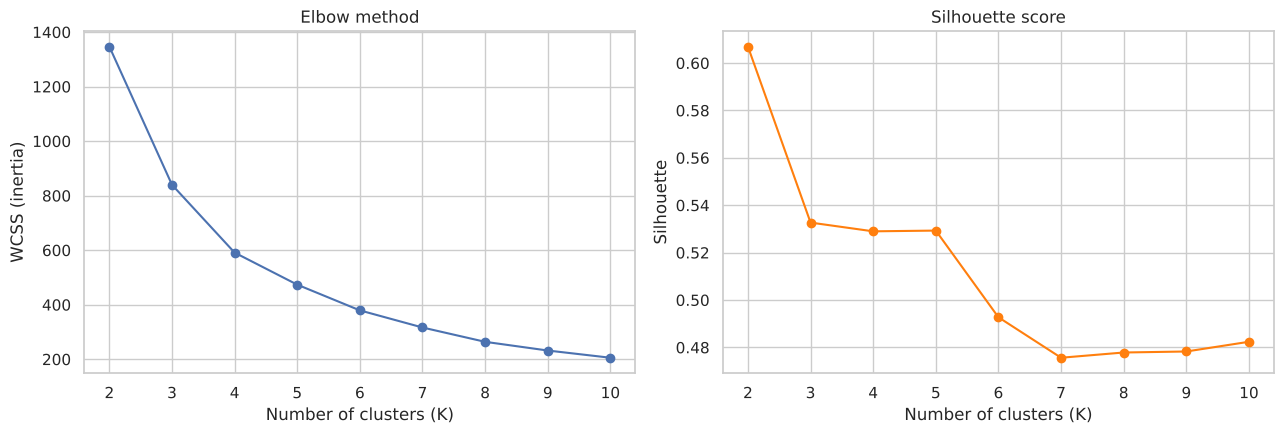

K=2: silhouette = 0.6070
K=3: silhouette = 0.5327
K=4: silhouette = 0.5290
K=5: silhouette = 0.5293
K=6: silhouette = 0.4927
K=7: silhouette = 0.4756
K=8: silhouette = 0.4779
K=9: silhouette = 0.4783
K=10: silhouette = 0.4824


In [4]:
K_RANGE = range(2, 11)
wcss, sil = [], []
for k in K_RANGE:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(X)
    wcss.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(list(K_RANGE), wcss, marker="o")
axes[0].set(title="Elbow method", xlabel="Number of clusters (K)", ylabel="WCSS (inertia)")
axes[1].plot(list(K_RANGE), sil, marker="o", color="tab:orange")
axes[1].set(title="Silhouette score", xlabel="Number of clusters (K)", ylabel="Silhouette")
plt.tight_layout()
plt.savefig("../images/kmeans_k_selection.png", dpi=150, bbox_inches="tight")
plt.show()

for k, s in zip(K_RANGE, sil):
    print(f"K={k}: silhouette = {s:.4f}")

### Choosing K = 3

Silhouette alone prefers **K = 2** (it simply splits low spenders from high spenders). K = 3 was chosen deliberately because a three-tier segmentation (low / mid / high value) is more useful for marketing, and its silhouette is still strong. This is a business decision, not the purely statistical optimum.

In [5]:
best_k = list(K_RANGE)[int(np.argmax(sil))]
K_FINAL = 3
print(f"Best K by silhouette : {best_k}  (silhouette = {max(sil):.4f})")
print(f"K used               : {K_FINAL}  (silhouette = {sil[list(K_RANGE).index(K_FINAL)]:.4f})")

Best K by silhouette : 2  (silhouette = 0.6070)
K used               : 3  (silhouette = 0.5327)


## 5. Fit the final model

In [6]:
kmeans = KMeans(n_clusters=K_FINAL, random_state=SEED, n_init=10).fit(X)
df["cluster"] = kmeans.labels_

# Name the segments by average spending (so names never depend on arbitrary cluster ids)
order = df.groupby("cluster")["total_spent"].mean().sort_values().index
SEGMENT_NAMES = dict(zip(order, ["Budget", "Regular", "Premium"]))
df["segment"] = df["cluster"].map(SEGMENT_NAMES)

print(f"Final silhouette score: {silhouette_score(X, kmeans.labels_):.4f}")

Final silhouette score: 0.5327


## 6. Visualize the segments

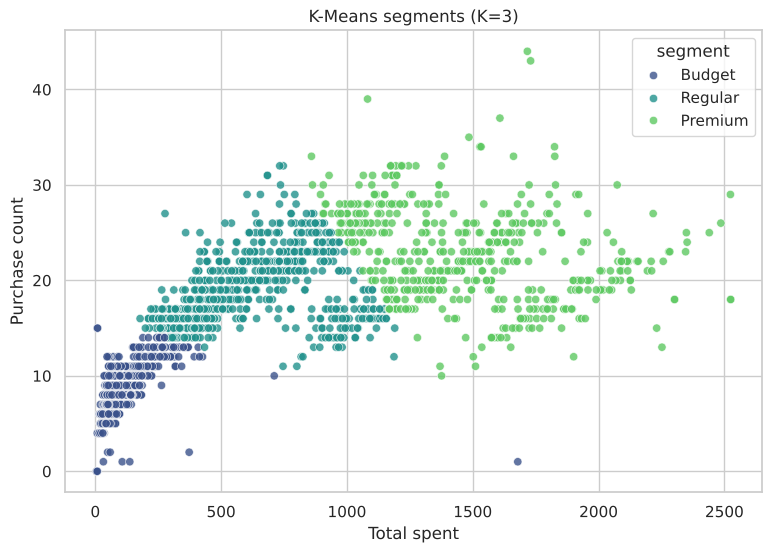

In [7]:
seg_order = ["Budget", "Regular", "Premium"]
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="total_spent", y="purchase_count", hue="segment",
                hue_order=seg_order, palette="viridis", alpha=0.8)
plt.title("K-Means segments (K=3)")
plt.xlabel("Total spent")
plt.ylabel("Purchase count")
plt.savefig("../images/kmeans_clusters.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Segment profiles

In [8]:
profile = (df.groupby("segment")
             .agg(customers=("segment", "size"),
                  avg_total_spent=("total_spent", "mean"),
                  avg_purchase_count=("purchase_count", "mean"),
                  avg_income=("Income", "mean"),
                  avg_recency_days=("Recency", "mean"))
             .loc[seg_order].round(2))
profile["share_%"] = (profile["customers"] / len(df) * 100).round(1)
profile

,customers,avg_total_spent,avg_purchase_count,avg_income,avg_recency_days,share_%
segment,,,,,,
Budget,1007,91.32,7.55,35739.01,49.10,45.0
Regular,659,640.57,19.22,58168.29,48.89,29.4
Premium,574,1468.45,22.69,74374.53,49.37,25.6


## 8. Predict the segment of a new customer

In [9]:
def predict_segment(total_spent, purchase_count):
    """Return the K-Means segment name for a new customer."""
    point = pd.DataFrame([[total_spent, purchase_count]], columns=FEATURES)
    return SEGMENT_NAMES[int(kmeans.predict(scaler.transform(point))[0])]

for spent, n in [(50, 5), (700, 20), (1800, 25)]:
    print(f"total_spent={spent:>5}, purchase_count={n:>3} -> {predict_segment(spent, n)}")

total_spent=   50, purchase_count=  5 -> Budget
total_spent=  700, purchase_count= 20 -> Regular
total_spent= 1800, purchase_count= 25 -> Premium
